In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import *
from sklearn.dummy import DummyClassifier

In [2]:
cancer = load_breast_cancer(as_frame=True)

df = cancer.frame

df.head()

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
print("Dataset Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nStatistical Summary:")
display(df.describe())

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nDuplicate Records:")
print(df.duplicated().sum())

Dataset Shape: (569, 31)

Columns:
['mean radius', 'mean texture', 'mean perimeter', 'mean area', 'mean smoothness', 'mean compactness', 'mean concavity', 'mean concave points', 'mean symmetry', 'mean fractal dimension', 'radius error', 'texture error', 'perimeter error', 'area error', 'smoothness error', 'compactness error', 'concavity error', 'concave points error', 'symmetry error', 'fractal dimension error', 'worst radius', 'worst texture', 'worst perimeter', 'worst area', 'worst smoothness', 'worst compactness', 'worst concavity', 'worst concave points', 'worst symmetry', 'worst fractal dimension', 'target']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 no

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,0.627417
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,0.483918
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,0.000000
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,0.000000
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,1.000000
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,1.000000
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,1.000000



Missing Values:
0

Duplicate Records:
0


In [4]:
print(df['target'].value_counts())

print("\nTarget Names:")
print(cancer.target_names)

target
1    357
0    212
Name: count, dtype: int64

Target Names:
['malignant' 'benign']


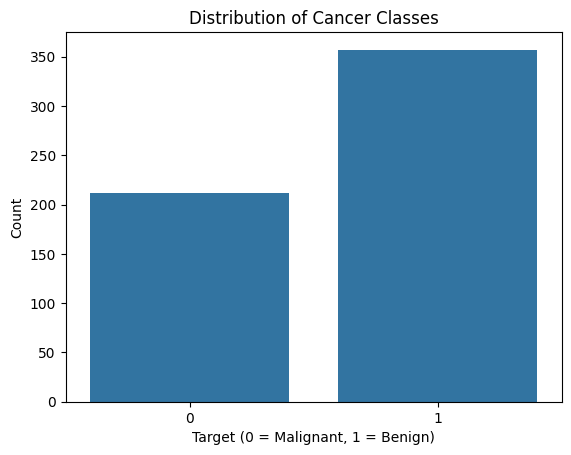

In [5]:
sns.countplot(x='target', data=df)

plt.title("Distribution of Cancer Classes")
plt.xlabel("Target (0 = Malignant, 1 = Benign)")
plt.ylabel("Count")
plt.show()

In [6]:
X = df.drop('target', axis=1)
y = (df['target'] == 0).astype(int)

print("Features Shape:", X.shape)
print("Target Shape:", y.shape)

Features Shape: (569, 30)
Target Shape: (569,)


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Shape:", X_train.shape)
print("Testing Shape:", X_test.shape)

print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())

Training Shape: (455, 30)
Testing Shape: (114, 30)

Training Class Distribution:
target
0    285
1    170
Name: count, dtype: int64

Testing Class Distribution:
target
0    72
1    42
Name: count, dtype: int64


In [8]:
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

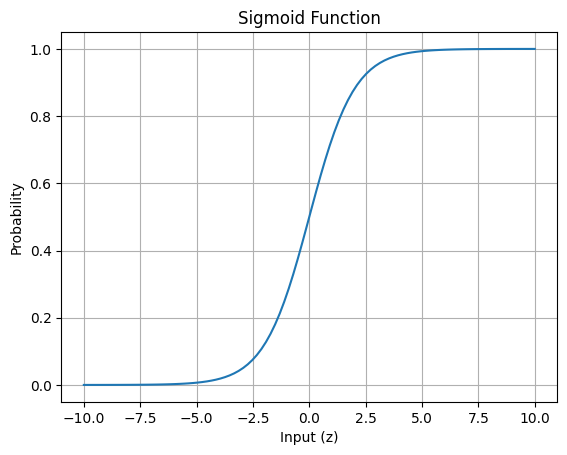

In [9]:
z = np.linspace(-10, 10, 100)

sigmoid = 1 / (1 + np.exp(-z))

plt.plot(z, sigmoid)

plt.title("Sigmoid Function")
plt.xlabel("Input (z)")
plt.ylabel("Probability")
plt.grid()
plt.show()

In [10]:
model = LogisticRegression(max_iter=1000)

model.fit(X_train_scaled, y_train)

print("Model Training Completed!")

Model Training Completed!


In [11]:
print("Intercept:", model.intercept_[0])

coefficients = pd.DataFrame({
    'Feature': X.columns,
    'Coefficient': model.coef_[0]
})

display(coefficients)

Intercept: -0.2430053269056021


,Feature,Coefficient
0,mean radius,0.361150
1,mean texture,0.482219
2,mean perimeter,0.353160
3,mean area,0.439950
4,mean smoothness,0.350622
5,mean compactness,-0.439546
6,mean concavity,0.782298
7,mean concave points,0.952813
8,mean symmetry,-0.163991
9,mean fractal dimension,-0.080865


In [12]:
y_prob = model.predict_proba(X_test_scaled)[:, 1]

y_pred = (y_prob >= 0.5).astype(int)

results = pd.DataFrame({
    'Actual': y_test.values,
    'Predicted Probability': y_prob,
    'Predicted Label': y_pred
})

display(results.head(10))

,Actual,Predicted Probability,Predicted Label
0,0,0.000365,0
1,1,1.000000,1
2,0,0.042568,0
3,1,0.576187,1
4,0,0.509155,1
5,0,0.000616,0
6,1,0.761534,1
7,0,0.001012,0
8,0,0.000569,0
9,0,0.010768,0


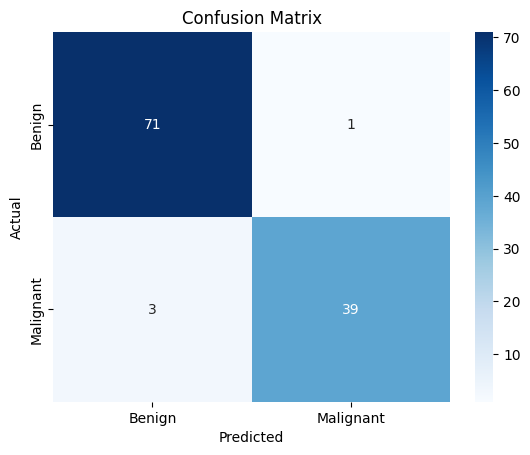

In [13]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Benign', 'Malignant'],
    yticklabels=['Benign', 'Malignant']
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix")
plt.show()

In [14]:
tn, fp, fn, tp = confusion_matrix(y_test, y_pred).ravel()

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
specificity = tn / (tn + fp)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_prob)

print("Accuracy:", accuracy)
print("Precision:", precision)
print("Recall:", recall)
print("Specificity:", specificity)
print("F1 Score:", f1)
print("ROC-AUC:", roc_auc)

Accuracy: 0.9649122807017544
Precision: 0.975
Recall: 0.9285714285714286
Specificity: 0.9861111111111112
F1 Score: 0.9512195121951219
ROC-AUC: 0.996031746031746


In [15]:
print(classification_report(
    y_test,
    y_pred,
    target_names=['Benign', 'Malignant']
))

              precision    recall  f1-score   support

      Benign       0.96      0.99      0.97        72
   Malignant       0.97      0.93      0.95        42

    accuracy                           0.96       114
   macro avg       0.97      0.96      0.96       114
weighted avg       0.97      0.96      0.96       114



In [16]:
baseline = DummyClassifier(strategy='most_frequent')

baseline.fit(X_train_scaled, y_train)

baseline_pred = baseline.predict(X_test_scaled)

print("Baseline Accuracy:",
      accuracy_score(y_test, baseline_pred))

print("Logistic Regression Accuracy:",
      accuracy_score(y_test, y_pred))

Baseline Accuracy: 0.631578947368421
Logistic Regression Accuracy: 0.9649122807017544


In [17]:
thresholds = [0.3, 0.5, 0.7]

for threshold in thresholds:

    pred = (y_prob >= threshold).astype(int)

    print("\nThreshold:", threshold)
    print("Accuracy:", accuracy_score(y_test, pred))
    print("Precision:", precision_score(y_test, pred))
    print("Recall:", recall_score(y_test, pred))
    print("F1 Score:", f1_score(y_test, pred))
    print("Predicted Positive:", sum(pred))


Threshold: 0.3
Accuracy: 0.9824561403508771
Precision: 0.9761904761904762
Recall: 0.9761904761904762
F1 Score: 0.9761904761904762
Predicted Positive: 42

Threshold: 0.5
Accuracy: 0.9649122807017544
Precision: 0.975
Recall: 0.9285714285714286
F1 Score: 0.9512195121951219
Predicted Positive: 40

Threshold: 0.7
Accuracy: 0.9649122807017544
Precision: 1.0
Recall: 0.9047619047619048
F1 Score: 0.95
Predicted Positive: 38


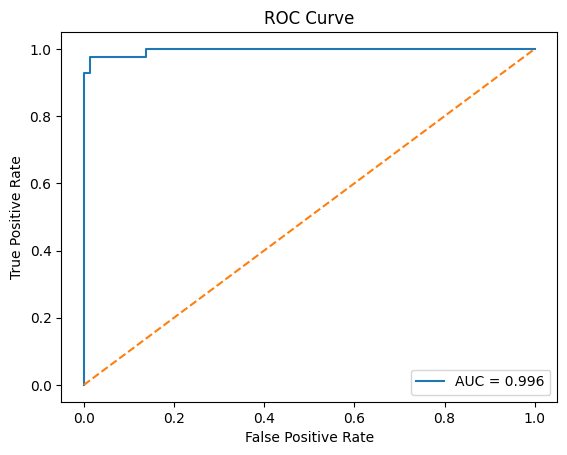

In [18]:
fpr, tpr, thresholds_roc = roc_curve(y_test, y_prob)

plt.plot(fpr, tpr, label=f"AUC = {roc_auc:.3f}")
plt.plot([0, 1], [0, 1], linestyle='--')

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.show()

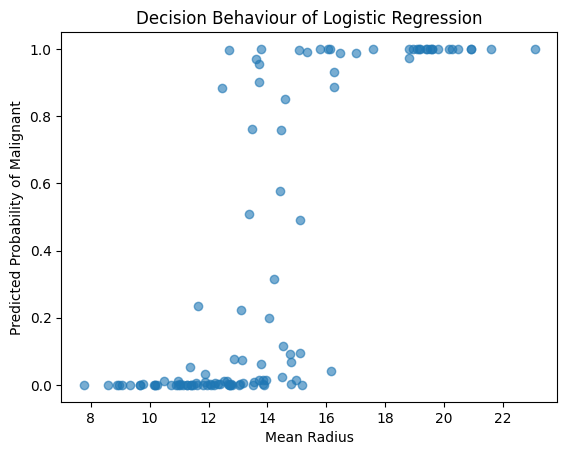

In [19]:
plt.scatter(
    X_test['mean radius'],
    y_prob,
    alpha=0.6
)

plt.xlabel("Mean Radius")
plt.ylabel("Predicted Probability of Malignant")
plt.title("Decision Behaviour of Logistic Regression")
plt.show()

In [20]:
new_sample = pd.DataFrame(
    [X.median().values],
    columns=X.columns
)

new_sample_scaled = scaler.transform(new_sample)

probability = model.predict_proba(new_sample_scaled)[0][1]

prediction = 1 if probability >= 0.5 else 0

print("Probability of Malignant:", probability)
print("Predicted Class:",
      "Malignant" if prediction == 1 else "Benign")

Probability of Malignant: 0.04759109850136573
Predicted Class: Benign
